   <a href="https://colab.research.google.com/github/IBM/vLLM-Hook/blob/main/notebooks/demo_langneuron_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Language-Specific Neurons with MLP Capture

vLLM-Hook is an extensible framework that aims to allow selective access to model internals during inference.
In this notebook, we demonstrate how vLLM-Hook captures **individual MLP neurons** (`hs_target="mlp"`) inside the CUDA-graph serving path, and use it to find **language-specific neurons**.

**Paper**: [Language-Specific Neurons: The Key to Multilingual Capabilities in Large Language Models](https://aclanthology.org/2024.acl-long.309/).<br />
**Authors**: Tianyi Tang, Wenyang Luo, Haoyang Huang, Dongdong Zhang, Xiaolei Wang, Wayne Xin Zhao, Furu Wei, Ji-Rong Wen.<br />
**"TL;DR"**: For each MLP neuron, measure how often it activates on text in each language, and score it by the entropy of those activation probabilities (LAPE, *language activation probability entropy*). Neurons with the lowest entropy fire for one or two languages only. The paper finds them mostly in the bottom and top layers of the model.

**What `hs_target="mlp"` captures**: for each decoder layer, the output of `mlp.act_fn`, i.e. `act(gate) * up`, the input of `down_proj`. Its width is the model's `intermediate_size` (9,216 for Qwen3.5-4B). It needs a dense MLP and `tensor_parallel_size=1`.

**Differences from the paper**, to keep the demo small:
- The paper counts a neuron as active when `act(gate) > 0`. MIA captures `act(gate) * up`, so here a neuron is active when that product is `> 0`.
- The paper uses 100M Wikipedia tokens per language. Here we use a few hundred passages per language from [Belebele](https://huggingface.co/datasets/facebook/belebele) (FLORES passages, the same content translated into every language), so the languages differ in language, not topic.

**Hardware**: Qwen3.5-4B needs about 9 GB in bfloat16. Use an L4 or A100 Colab runtime (a T4 lacks bfloat16).

### Installation

If running this from a Colab runtime, use the setup cell below to install MIA from this repository.

The following blockl is not necessary if running the notebook from an enviornment where MIA has already been installed.

In [1]:
from pathlib import Path
import importlib
import importlib.util
import os
import shutil
import subprocess
import sys
import time

REPO_URL = "https://github.com/IBM/vLLM-Hook.git"
REPO_BRANCH = "main"
REPO_NAME = "vLLM-Hook"

IN_COLAB = "google.colab" in sys.modules
NOTEBOOK_DIR = Path.cwd()

def run(cmd, cwd=None, env=None):
  """Execute the shell command and print output in real time"""
  cmd = [str(part) for part in cmd]
  print(f"> Running: {' '.join(cmd)}", flush=True)

  process = subprocess.Popen(
      cmd,
      cwd=str(cwd) if cwd else None,
      env=env,
      stdout=subprocess.PIPE,
      stderr=subprocess.STDOUT,
      text=True,
      bufsize=1,
  )

  tail = []
  assert process.stdout is not None
  for line in process.stdout:
    print(line, end="", flush=True)
    tail.append(line.rstrip())
    tail = tail[-120:]

  returncode = process.wait()
  if returncode:
    tail_text = "\n".join(tail)
    raise RuntimeError(
        f"Command failed with exit code {returncode}: {' '.join(cmd)}\n\n"
        f"Last output lines: \n{tail_text}"
    )

def _repo_remote_matches(repo_root: Path, expected_remote: str) -> bool:
    try:
        url = subprocess.run(
            ["git", "-C", str(repo_root), "remote", "get-url", "origin"],
            check=True,
            capture_output=True,
            text=True,
        ).stdout.strip().removesuffix(".git")
    except Exception:
        return False
    return url == expected_remote


def _find_existing_repo_root(start_dir: Path, expected_remote: str):
    for candidate in [start_dir, *start_dir.parents]:
        if (candidate / ".git").exists() and _repo_remote_matches(candidate, expected_remote):
            return candidate
    return None


def assert_cuda_runtime():
    try:
        import torch
    except Exception:
        torch = None

    has_cuda = bool(torch is not None and torch.cuda.is_available())
    has_cudart = importlib.util.find_spec("nvidia.cuda_runtime") is not None

    if not has_cuda and not has_cudart:
        raise RuntimeError(
            "No CUDA GPU detected. In Colab, go to Runtime > Change runtime type, "
            "select a GPU, then re-run the notebook from the beginning."
        )


expected_remote = REPO_URL.removesuffix(".git")
existing_repo_root = _find_existing_repo_root(NOTEBOOK_DIR, expected_remote)

if IN_COLAB:
    if existing_repo_root is not None:
        REPO_ROOT = existing_repo_root
        print(f"✓ Reusing existing repo at: {REPO_ROOT}")
    else:
        REPO_ROOT = Path("/content") / REPO_NAME
        if not REPO_ROOT.exists():
            print(f"Cloning {REPO_URL} (branch: {REPO_BRANCH})...")
            run(["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO_ROOT)])
        elif not _repo_remote_matches(REPO_ROOT, expected_remote):
            print("Remote mismatch detected. Replacing clone...")
            shutil.rmtree(REPO_ROOT)
            run(["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(REPO_ROOT)])
        else:
            print("Refreshing existing clone...")
            run(["git", "-C", str(REPO_ROOT), "fetch", "origin", REPO_BRANCH])
            run(["git", "-C", str(REPO_ROOT), "checkout", REPO_BRANCH])
            run(["git", "-C", str(REPO_ROOT), "pull", "--ff-only", "origin", REPO_BRANCH])

    NOTEBOOK_DIR = REPO_ROOT / "notebooks"
    os.chdir(NOTEBOOK_DIR)
    print(f"Working directory set to: {NOTEBOOK_DIR}")
else:
    REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

REQ_FILE = REPO_ROOT / "requirement.txt"
COLAB_RESTART_MARKER = Path("/tmp/mia_colab_binary_deps_restarted")

print("\n--- Environment Summary ---")
print(f"Running in Colab: {IN_COLAB}")
print(f"Repo Root: {REPO_ROOT}")

if IN_COLAB:
    assert_cuda_runtime()

if shutil.which("git") is None and IN_COLAB:
    raise RuntimeError("git is required but unavailable in this runtime.")

print("Installing validated MIA dependencies from requirement.txt...")
run([sys.executable, "-m", "pip", "install", "-r", str(REQ_FILE)])

# vLLM installs torchcodec for audio/video decoding; MIA does not use it.
# Removing it matches the repository install instructions and avoids pip-check noise.
run([sys.executable, "-m", "pip", "uninstall", "-y", "torchcodec"])

print("Registering MIA package in editable mode...")
run([sys.executable, "-m", "pip", "install", "--no-deps", "-e", str(REPO_ROOT)])

repo_root_str = str(REPO_ROOT.resolve())
if repo_root_str not in sys.path:
    sys.path.insert(0, repo_root_str)
importlib.invalidate_caches()

print("\nVerifying installation...")
run([
    sys.executable,
    "-c",
    "import torch, vllm, mia; print('✓ torch:', torch.__version__); print('✓ vllm:', getattr(vllm, '__version__', 'unknown')); print('✓ mia:', mia.__file__)",
])

if IN_COLAB and not COLAB_RESTART_MARKER.exists():
  COLAB_RESTART_MARKER.write_text("1\n")
  print("\n" + "=" * 50)
  print("RESTARTING COLAB RUNTIME...")
  print("This ensures the new vLLM/Torch binaries are fully loaded.")
  print("After restart, continue by re-running this setup cell, then run the rest.")
  print("=" * 50)
  time.sleep(1)
  sys.exit(0)

Refreshing existing clone...
> Running: git -C /content/vLLM-Hook fetch origin feat/hs-target-mlp
From https://github.com/akshitsrivastava04/vLLM-Hook
 * branch            feat/hs-target-mlp -> FETCH_HEAD
> Running: git -C /content/vLLM-Hook checkout feat/hs-target-mlp
Already on 'feat/hs-target-mlp'
Your branch is up to date with 'origin/feat/hs-target-mlp'.
> Running: git -C /content/vLLM-Hook pull --ff-only origin feat/hs-target-mlp
From https://github.com/akshitsrivastava04/vLLM-Hook
 * branch            feat/hs-target-mlp -> FETCH_HEAD
Already up to date.
Working directory set to: /content/vLLM-Hook/notebooks

--- Environment Summary ---
Running in Colab: True
Repo Root: /content/vLLM-Hook
Installing validated MIA dependencies from requirement.txt...
> Running: /usr/bin/python3 -m pip install -r /content/vLLM-Hook/requirement.txt
  Using cached torchcodec-0.17.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.9 kB)
Using cached torchcodec-0.17.0-cp313-cp313

### Importing the MIA LLM
MIA provides `MiaLLM`, a vLLM wrapper for capture and steering.

In [2]:
from mia import MiaLLM

### Environment & multiprocessing setup

In [3]:
import gc
import io
import json
import multiprocessing as mp
import os
import sys
import time
from pathlib import Path

import torch
from vllm import SamplingParams

IN_COLAB = "google.colab" in sys.modules
mp.set_start_method("spawn", force=True)
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

# In notebooks, vLLM's separate EngineCore process can hide the real startup
# exception behind "Engine core initialization failed". Keep the engine in this
# process for Colab so failures are visible and startup is less brittle.
if IN_COLAB:
    os.environ["VLLM_ENABLE_V1_MULTIPROCESSING"] = "0"

if IN_COLAB:
    os.environ.setdefault("HF_HOME", "/content/.cache/huggingface")
    os.environ.setdefault("HUGGINGFACE_HUB_CACHE", "/content/.cache/huggingface/hub")
    os.makedirs(os.environ["HUGGINGFACE_HUB_CACHE"], exist_ok=True)
    os.makedirs("/content/.cache/mia", exist_ok=True)

    def _patch_fileno(stream, fallback_stream, fallback_fd):
        try:
            stream.fileno()
        except io.UnsupportedOperation:
            def _fileno():
                try:
                    return fallback_stream.fileno()
                except Exception:
                    return fallback_fd
            stream.fileno = _fileno

    _patch_fileno(sys.stdout, sys.__stdout__, 1)
    _patch_fileno(sys.stderr, sys.__stderr__, 2)
    print("Colab detected: using spawn start method with in-process vLLM EngineCore")

# vLLM can sample with a FlashInfer kernel that it compiles on first use; that build fails on
# some machines. Sampling happens after the forward pass, so the capture does not depend on it.
os.environ.setdefault("VLLM_USE_FLASHINFER_SAMPLER", "0")

Colab detected: using spawn start method with in-process vLLM EngineCore


'0'

### Configuration
The same seven languages as the paper. `N_TRAIN` passages per language are used to find the neurons; `N_TEST` different passages are kept aside to check them.

In [4]:
import numpy as np

cache_dir = "/content/.cache/mia" if IN_COLAB else str(Path("~/.cache/mia").expanduser())
model = "Qwen/Qwen3.5-4B"

LANGS = {
    "en": "eng_Latn", "zh": "zho_Hans", "fr": "fra_Latn", "es": "spa_Latn",
    "vi": "vie_Latn", "id": "ind_Latn", "ja": "jpn_Jpan",
}
N_TRAIN, N_TEST = 150, 30
BATCH = 4

MAX_MODEL_LEN = int(os.environ.get("MIA_COLAB_MAX_MODEL_LEN", "1024"))
GPU_MEMORY_UTILIZATION = float(os.environ.get("MIA_COLAB_GPU_MEMORY_UTILIZATION", "0.85"))

# GPU buffer MIA captures into, outside vLLM's gpu_memory_utilization share. Each captured token
# costs 32 layers x 9,216 neurons x 2 bytes = 0.59 MB; 1 GiB covers a full 1,024-token batch step.
# The automatic size (4 GiB on an L4) does not fit next to the model at 0.85 utilization.
os.environ.setdefault("MIA_APERTURE_GPU_BYTES", str(5 << 29))

# This notebook runs MIA's default CUDA-graph path, since capturing MLP neurons under CUDA graphs
# is what it demonstrates. Set to True to use eager mode instead; the captured values are the same.
ENFORCE_EAGER = False

##Data
Belebele pairs several questions with each passage, so passages repeat; we keep each passage once.

In [5]:
from datasets import load_dataset

texts = {}
for lang, config in LANGS.items():
    rows = load_dataset("facebook/belebele", config, split="test")
    passages = list(dict.fromkeys(rows["flores_passage"]))       # unique, in order
    texts[lang] = {"train": passages[:N_TRAIN], "test": passages[N_TRAIN:N_TRAIN + N_TEST]}
    print(f"{lang}: {len(passages)} unique passages | e.g. {passages[0][:70]!r}")

README.md:   0%|          | 0.00/25.5k [00:00<?, ?B/s]

eng_Latn.jsonl:   0%|          | 0.00/836k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

en: 488 unique passages | e.g. 'Make sure your hand is as relaxed as possible while still hitting all '


zho_Hans.jsonl:   0%|          | 0.00/1.29M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

... (12 outputs left out)

id: 488 unique passages | e.g. '"""Iya Raja Tutankhamun, terkadang disebut sebagai ""Raja Tut"" atau "'


jpn_Jpan.jsonl:   0%|          | 0.00/1.72M [00:00<?, ?B/s]

Generating test split:   0%|          | 0/900 [00:00<?, ? examples/s]

ja: 488 unique passages | e.g. '音符どおりに正確に奏でながら、手をできるだけリラックスした状態で保つようにしましょう。また、指が余計な動きをしないように努めましょう。 そう'


Before building `MiaLLM` clear any stale CUDA allocations left by earlier runs in the same session.

In [6]:
try:
    del llm
except NameError:
    pass

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

### Initialize `MiaLLM`
`worker_name="capture_hs"` with `hs_target="mlp"` captures MLP neurons instead of decoder-layer outputs. With no config file, every layer is captured.

In [7]:
llm = MiaLLM(
    model=model,
    worker_name="capture_hs",
    analyzer_name="hidden_states",
    hs_target="mlp",
    download_dir=cache_dir,
    dtype="auto",
    gpu_memory_utilization=GPU_MEMORY_UTILIZATION,
    max_model_len=MAX_MODEL_LEN,
    max_num_batched_tokens=MAX_MODEL_LEN,
    enforce_eager=ENFORCE_EAGER,
    tensor_parallel_size=1,
    enable_prefix_caching=False,
)

(MainProcess pid=4661) INFO 11-12 18:45:50 [api_utils.py:286] non-default args: {'download_dir': '/content/.cache/mia', 'max_model_len': 1024, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.85, 'max_num_batched_tokens': 1024, 'disable_log_stats': True, 'worker_extension_cls': 'mia.workers.hs_capture_worker.HSCaptureWorker', 'model': 'Qwen/Qwen3.5-4B'}
[mia] compile-cache key stamped with worker=hidden_states mia=0.6.0-ee6487b layout={"aperture_gpu_bytes": "2684354560", "hs_all_ranks_env": "", "hs_capture_mode": "buffer", "hs_layer_shard_rule": "none", "hs_layout": "single", "hs_owned_layers": "every layer (single rank)", "hs_shard_env": "", "hs_sinks": false, "hs_target": "mlp", "kind": "hidden_states", "tp_size": 1} (worker_extension_cls is excluded from vLLM's own key)
[mia] capture mode: FULL_AND_PIECEWISE CUDA graph (chosen by default) -- graph mode chosen by default (enforce_eager=True or MIA_ALLOW_CUDAGRAPH=0 selects eager) mia=/content/vLLM-Hook/mia
[mia/delivery] p

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

(MainProcess pid=4661) WARNING 11-12 18:45:51 [arg_utils.py:1945] The global random seed is set to 0. Since VLLM_ENABLE_V1_MULTIPROCESSING is set to False, this may affect the random state of the Python process that launched vLLM.
(MainProcess pid=4661) INFO 11-12 18:46:08 [model.py:733] Resolved architecture: Qwen3_5ForConditionalGeneration
(MainProcess pid=4661) INFO 11-12 18:46:08 [model.py:2152] Using max model len 1024


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

... (11 outputs left out)

Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 14.86it/s]


(MainProcess pid=4661) INFO 11-12 18:50:23 [model_runner.py:1127] Graph capturing finished in 20 secs, took 0.24 GiB
(MainProcess pid=4661) INFO 11-12 18:50:23 [gpu_worker.py:971] CUDA graph pool memory: 0.24 GiB (actual), 0.48 GiB (estimated), difference: 0.24 GiB (101.7%).
(MainProcess pid=4661) INFO 11-12 18:50:23 [gpu_worker.py:1034] Free memory on device (19.31/22.03 GiB) on startup. Desired GPU memory utilization is (0.85, 18.73 GiB). Actual usage is 8.91 GiB for consumed memory (weights + non-torch), 2.08 GiB for peak activation, and 0.24 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=7896481280` (7.35 GiB) to fit into requested memory, or `--kv-cache-memory=8524021248` (7.94 GiB) to fully utilize gpu memory. Current kv cache memory in use is 7.74 GiB.
(MainProcess pid=4661) INFO 11-12 18:50:24 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(MainProcess pid=4661) INFO 11-1

[transformers] Qwen3VL video processing does not apply the per-frame pixel cap the reference implementation (qwen-vl-utils) applies, so some videos cost far more tokens than they would there. In v5.22 the capped behavior will become the default and `cap_pixels_per_frame` will be removed. Pass `cap_pixels_per_frame=True` to adopt the reference behavior now, or `False` to keep the current behavior and silence this warning.


(MainProcess pid=4661) INFO 11-12 18:50:49 [base.py:280] Multi-modal warmup completed in 23.878s


### Capture and count activations
Each passage is fed as plain text (no chat template, as in the paper's Wikipedia text). `max_tokens=1` runs the prompt only, and `hs_mode="all_tokens"` keeps every token.

The captures are large (every token × 32 layers × 9,216 neurons), so `count_active` keeps only, per language, how many tokens each neuron was active on, and drops the tensors.
It also checks that every request returned exactly one row per prompt token.

In [8]:
sp = SamplingParams(max_tokens=1, temperature=0.0, extra_args={"hs_mode": "all_tokens"})


def token_rows(entry) -> torch.Tensor:
    """One captured layer as a (tokens, neurons) tensor, without padding rows."""
    t = entry["hidden_states"]
    if isinstance(t, (list, tuple)):
        return torch.cat([x.reshape(-1, x.shape[-1]) for x in t if x is not None])
    if t.dim() == 3:
        lens = entry.get("pass_lens") or [t.shape[1]] * t.shape[0]
        return torch.cat([t[i, :int(n)] for i, n in enumerate(lens)])
    return t.reshape(-1, t.shape[-1])


def request_rows(entry, i) -> torch.Tensor:
    """Request i's (tokens, neurons) rows from the batch capture on the first output."""
    t = entry["hidden_states"]
    if isinstance(t, (list, tuple)):
        return t[i].reshape(-1, t[i].shape[-1])
    return token_rows(entry)


def count_active(passages):
    """Per neuron: number of tokens with activation > 0, summed over passages; and the token count."""
    active, n_tok = None, 0
    for start in range(0, len(passages), BATCH):
        outs = llm.generate(passages[start:start + BATCH], sp, use_tqdm=False)
        hs_cache = outs[0].probes["hs_cache"]
        layers = sorted(hs_cache, key=lambda k: int(hs_cache[k]["layer_num"]))
        for i, out in enumerate(outs):
            n = len(out.prompt_token_ids)
            rows = [request_rows(hs_cache[k], i) for k in layers]
            assert all(r.shape[0] == n for r in rows), (n, [r.shape[0] for r in rows][:3])
            counts = torch.stack([(r > 0).sum(0) for r in rows]).numpy()
            active = counts if active is None else active + counts
            n_tok += n
    return active, n_tok


probs = {}
for lang in LANGS:
    t0 = time.time()
    active, n_tok = count_active(texts[lang]["train"])
    probs[lang] = active / n_tok
    print(f"{lang}: {n_tok:,} tokens  {time.time() - t0:.0f} s")

P = np.stack([probs[l] for l in LANGS])
n_langs, n_layers, width = P.shape
print("activation probabilities:", P.shape)

en: 15,188 tokens  72 s
zh: 13,633 tokens  64 s
fr: 20,733 tokens  75 s
es: 19,896 tokens  72 s
vi: 19,257 tokens  71 s
id: 15,932 tokens  58 s
ja: 17,591 tokens  65 s
activation probabilities: (7, 32, 9216)


In [9]:
probe_prompts = ["Hello world.", "The quick brown fox jumps over the lazy dog today.", "One two three"]
for mode in ("all_tokens", "last_token"):
    outs = llm.generate(probe_prompts, SamplingParams(max_tokens=1, temperature=0.0, extra_args={"hs_mode": mode}), use_tqdm=False)
    first = []
    for o in outs:
        hs = o.probes["hs_cache"]; e = hs[sorted(hs, key=lambda k: int(hs[k]["layer_num"]))[0]]; t = e["hidden_states"]
        shape = tuple(t.shape) if hasattr(t, "shape") else [tuple(x.shape) for x in t]
        first.append(token_rows(e)[-1])
        print(mode, "| prompt tokens:", len(o.prompt_token_ids), "| captured:", shape, "| extra keys:", [k for k in e if k != "hidden_states"])
    print(mode, "| last rows identical across requests:", all(torch.equal(first[0], f) for f in first[1:]))

all_tokens | prompt tokens: 3 | captured: [(3, 9216), (11, 9216), (3, 9216)] | extra keys: ['layer_num', 'hs_mode', 'req_passes']
all_tokens | prompt tokens: 11 | captured: (1, 11, 9216) | extra keys: ['layer_num', 'hs_mode', 'pass_lens']
all_tokens | prompt tokens: 3 | captured: (1, 3, 9216) | extra keys: ['layer_num', 'hs_mode', 'pass_lens']
all_tokens | last rows identical across requests: False
last_token | prompt tokens: 3 | captured: [(9216,), (9216,), (9216,)] | extra keys: ['layer_num', 'hs_mode', 'req_passes']
last_token | prompt tokens: 11 | captured: (1, 9216) | extra keys: ['layer_num', 'hs_mode']
last_token | prompt tokens: 3 | captured: (1, 9216) | extra keys: ['layer_num', 'hs_mode']
last_token | last rows identical across requests: False


### LAPE
Following the paper: normalize each neuron's activation probabilities over languages into a distribution, take its entropy, keep neurons that are active often enough in at least one language (above the 95th percentile of all activation probabilities), and select the 1% of all neurons with the lowest entropy. A selected neuron is specific to every language in which its activation probability exceeds that same threshold.

In [10]:
threshold = np.quantile(P, 0.95)
dist = P / np.clip(P.sum(0, keepdims=True), 1e-12, None)
lape = -(dist * np.log(np.clip(dist, 1e-12, None))).sum(0)

eligible = P.max(0) > threshold
k = int(0.01 * n_layers * width)
order = np.argsort(np.where(eligible, lape, np.inf).ravel())[:k]
selected = np.zeros(n_layers * width, bool)
selected[order] = True
selected = selected.reshape(n_layers, width)

specific = {lang: selected & (P[i] > threshold) for i, lang in enumerate(LANGS)}
print(f"threshold (95th pct of activation probabilities): {threshold:.3f} | selected neurons: {k:,}")
for lang, mask in specific.items():
    print(f"  {lang}: {int(mask.sum()):5d} neurons")

threshold (95th pct of activation probabilities): 0.710 | selected neurons: 2,949
  en:   653 neurons
  zh:   669 neurons
  fr:   661 neurons
  es:   700 neurons
  vi:   825 neurons
  id:   726 neurons
  ja:   898 neurons


### Where do the published neurons land?
The paper finds language-specific neurons concentrated in the bottom and top layers.

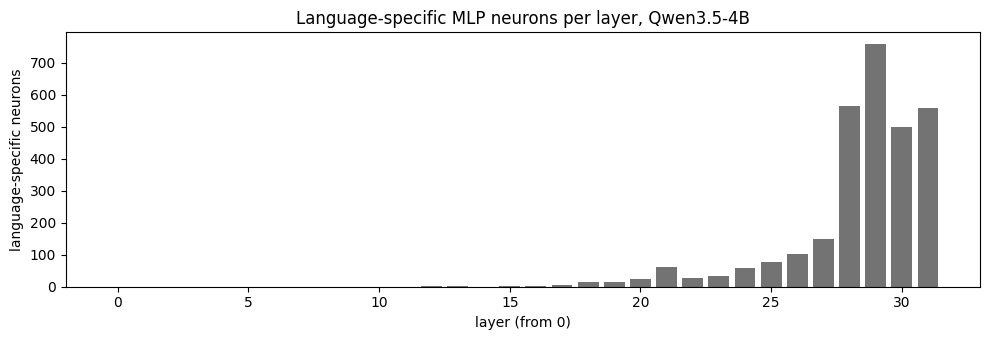

In [11]:
import matplotlib.pyplot as plt

per_layer = selected.sum(1)
plt.figure(figsize=(10, 3.5))
plt.bar(range(n_layers), per_layer, color="0.45")
plt.xlabel("layer (from 0)")
plt.ylabel("language-specific neurons")
plt.title("Language-specific MLP neurons per layer, Qwen3.5-4B")
plt.tight_layout()
plt.show()

### Do they hold on unseen text?
For held-out passages in each language, measure how often each language's neurons fire.
If the neurons are language-specific, each row should peak on the diagonal: Chinese text lights up the Chinese neurons, and so on.

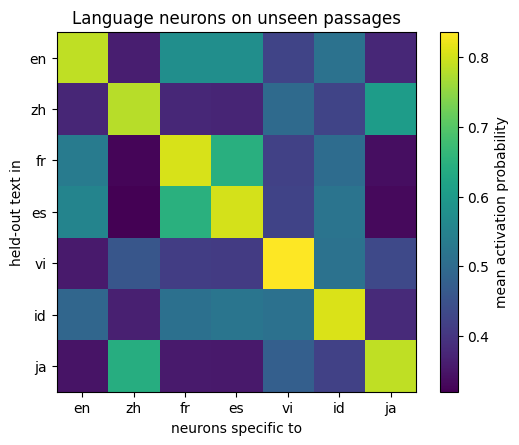

rows peaking on their own language: 7 of 7


In [12]:
test_probs = {lang: (lambda a, n: a / n)(*count_active(texts[lang]["test"])) for lang in LANGS}

names = list(LANGS)
M = np.array([[test_probs[a][specific[b]].mean() if specific[b].any() else np.nan for b in names]
              for a in names])

plt.figure(figsize=(5.5, 4.5))
plt.imshow(M, cmap="viridis")
plt.colorbar(label="mean activation probability")
plt.xticks(range(len(names)), names)
plt.yticks(range(len(names)), names)
plt.xlabel("neurons specific to")
plt.ylabel("held-out text in")
plt.title("Language neurons on unseen passages")
plt.tight_layout()
plt.show()

hits = int((np.nanargmax(M, axis=1) == np.arange(len(names))).sum())
print(f"rows peaking on their own language: {hits} of {len(names)}")

   ### Reading the result
   On this run (Qwen3.5-4B, 150 Belebele passages per language):
   - **Unseen text:** every row of the heatmap peaks on its own language (about 0.8 on the diagonal vs mostly 0.3–0.6 elsewhere), so neurons selected on one set of passages pick out the language of passages they have not seen.
   - **Overlap:** the largest off-diagonal entries are fr↔es and zh↔ja, related languages that share vocabulary or script.
   - **Layers:** the selected neurons sit almost entirely in the top layers (28–31), with few below layer 20. The paper reports both bottom and top layers; this run reproduces the top end only. Possible reasons, not tested here: the different activation rule (`act(gate) * up > 0` vs `act(gate) > 0`), a different model (Qwen3.5-4B mixes linear-attention layers), and far less data.

   Since `down_proj` is linear, changing neuron *n* of layer *l* by δ is the same as adding δ·`W_down[:, n]` to that layer's output, so the neurons found here can be tested causally with MIA's existing `steer` worker (the paper deactivates them and measures perplexity per language).